# 4 · Upscaling check: does a coarse model change the answer?

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, wells 16A(78)-32 / 16B(78)-32**

**Questions.** (1) Does the full permeability tensor (with its off-diagonal terms) change breakthrough and rate against the diagonal used in phase 3? (2) A 70 m model is usual practice for a reservoir this size. How much does it change the breakthrough time against the 23.3 m model of the same fractures, done the usual way and with KAI's upscaling? (3) What does the near-well part of the upscaling do?

**Labels.** All numbers are **simulated** (KAI Reservoir Lab, equivalent-continuum fractured granite). Breakthrough is the time the produced temperature has fallen by 5 % of (initial − reinjection) temperature, reinjection at 60 °C. P10–P90 over the members.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, FILL, GRANITE, BLUE = "#c9a227", "#26292e", "#d8c7a3", "#b5838d", "#2a78d6"     # KAI energy palette
pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase4.json").read_text())
PUB = json.loads(pathlib.Path("results/published_phase4.json").read_text()) if pathlib.Path("results/published_phase4.json").exists() else {}
ens = E["ensemble"]
def pct(d, f="{:.1f}"):
    return f"{f.format(d['P50'])} ({f.format(d['P10'])}–{f.format(d['P90'])})"
def check(now, key):
    pathlib.Path(f"results/{key}.json").write_text(json.dumps({"published": now}, indent=1))
    if key not in PUB:
        print(f"{key}: no published numbers yet; wrote results/{key}.json")
        return
    bad = []
    for k, v in PUB[key].items():
        x = now[k]
        if isinstance(v, (str, bool)) or v is None or isinstance(x, (str, bool)) or x is None:
            ok = x == v
        else:
            ok = abs(x - v) <= 0.02 * abs(v) + 1e-3
        if not ok:
            bad.append((k, x, v))
    assert not bad, bad
    print(f"all {len(PUB[key])} published numbers reproduced")
print(f"{ens['members'] - ens['failed']}/{ens['members']} members ran; engine results generated {E['generated']}")

20/20 members ran; engine results generated 2026-10-30


## 1 · Full tensor against diagonal

The median member, each scheme calibrated on its own to the August 2024 injection pressure, on 35 m and 23.3 m cells. The full tensor is the Oda tensor with its cross terms (TPFA plus a cross-flux correction); off-diagonal terms reach about 0.4 of the diagonal in the stimulated cells.

In [2]:
FT = E["full_tensor"]
rows = []
for r in FT["runs"]:
    for q, f in r["forecast"].items():
        rows.append({"cells (m)": round(r["cell_m"], 1), "scheme": r["scheme"], "rate (kg/s)": int(q), "aperture factor λ": round(r["stim_aperture_factor"], 4),
                     "breakthrough (years)": round(f["breakthrough_years"], 3), "T year 30 (°C)": round(f["T_prod_end_c"], 1),
                     "injector BHP max (MPa)": round(f["injector_bhp_max_mpa"], 2), "tracer peak (h)": round(r["tracer"]["peak_time_h"], 3)})
tab = pd.DataFrame(rows); display(tab)
chg = {}
for c in FT["cells_m"]:
    d = [r for r in FT["runs"] if abs(r["cell_m"] - c) < 1e-6]
    dg, fl = (next(r for r in d if r["scheme"].startswith(s)) for s in ("diagonal", "full"))
    for q in dg["forecast"]:
        chg[f"{c:.1f}_{q}"] = {"breakthrough": fl["forecast"][q]["breakthrough_years"] / dg["forecast"][q]["breakthrough_years"] - 1,
                               "T30_c": fl["forecast"][q]["T_prod_end_c"] - dg["forecast"][q]["T_prod_end_c"],
                               "lambda": fl["stim_aperture_factor"] / dg["stim_aperture_factor"] - 1}
for k, v in chg.items():
    c, q = k.split("_")
    print(f"{c} m, {q} kg/s: full tensor changes breakthrough by {v['breakthrough']:+.1%}, 30-year temperature by {v['T30_c']:+.1f} °C, calibrated λ by {v['lambda']:+.1%}")

,cells (m),scheme,rate (kg/s),aperture factor λ,breakthrough (years),T year 30 (°C),injector BHP max (MPa),tracer peak (h)
0,35.0,diagonal (TPFA),10,0.1498,0.542,119.0,39.42,0.5
1,35.0,diagonal (TPFA),20,0.1498,0.262,103.8,60.79,0.5
2,35.0,full tensor (TPFA + cross terms),10,0.1471,0.586,117.4,39.46,0.5
3,35.0,full tensor (TPFA + cross terms),20,0.1471,0.283,102.2,60.83,0.5
4,23.3,diagonal (TPFA),10,0.1674,0.862,120.8,38.47,0.5
5,23.3,diagonal (TPFA),20,0.1674,0.382,102.4,58.25,0.5
6,23.3,full tensor (TPFA + cross terms),10,0.1613,0.856,119.2,38.53,0.5
7,23.3,full tensor (TPFA + cross terms),20,0.1613,0.378,101.9,58.07,0.5


35.0 m, 10 kg/s: full tensor changes breakthrough by +8.1%, 30-year temperature by -1.6 °C, calibrated λ by -1.8%
35.0 m, 20 kg/s: full tensor changes breakthrough by +7.8%, 30-year temperature by -1.5 °C, calibrated λ by -1.8%
23.3 m, 10 kg/s: full tensor changes breakthrough by -0.8%, 30-year temperature by -1.6 °C, calibrated λ by -3.6%
23.3 m, 20 kg/s: full tensor changes breakthrough by -1.1%, 30-year temperature by -0.6 °C, calibrated λ by -3.6%


Calibration absorbs most of the difference: both schemes are fitted to the same measured pressure, so the full tensor mostly moves λ. What remains is the change in *where* the water goes, which shows in the breakthrough time.

## 2 · Coarse against fine

Each of the first members of the ensemble is built twice from the same fracture network: on 23.3 m cells (the reference) and on 70 m cells. The 70 m model is then used two ways:

* **usual practice**: the Oda tensor of the same fractures on 70 m cells, Peaceman well indices, recalibrated on the August test;
* **KAI**: transmissibilities and well indices upscaled from the fine model's own well-pair solution (global plus near-well upscaling), *not* recalibrated.

Rates are balanced (injection = production) for 30 years.

,rate (kg/s),fine 23.3 m: breakthrough (y),70 m usual (y),70 m usual vs fine,70 m KAI (y),70 m KAI vs fine,T30 change usual (°C),T30 change KAI (°C)
0,10,1.67 (1.28–1.85),2.04 (1.12–2.78),+25% (-32%–+62%),2.54 (1.35–3.21),+54% (-26%–+115%),10.8 (3.1–14.2),2.4 (-0.0–5.1)
1,40,0.36 (0.28–0.39),0.49 (0.27–0.68),+39% (-26%–+84%),0.60 (0.32–0.76),+72% (-16%–+141%),5.9 (0.4–8.8),-3.6 (-4.6–-1.3)


members: 12/12 ok


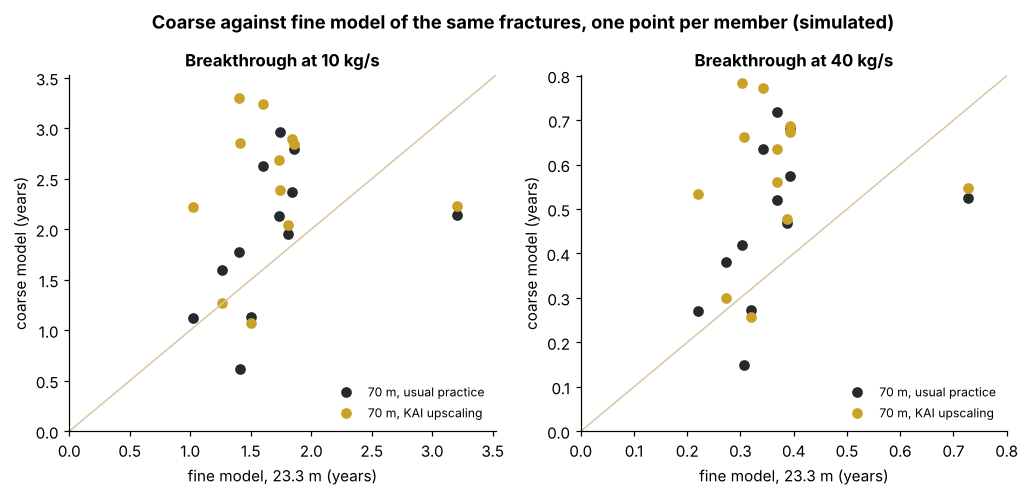

In [3]:
U = E["upscaling"]
rows = []
for q, d in U["rates"].items():
    rows.append({"rate (kg/s)": int(q), "fine 23.3 m: breakthrough (y)": pct(d["fine"]["breakthrough_years"], "{:.2f}"),
                 "70 m usual (y)": pct(d["coarse_usual"]["breakthrough_years"], "{:.2f}"), "70 m usual vs fine": pct({k: 100 * v for k, v in d["coarse_usual"]["breakthrough_change"].items() if k in ("P10", "P50", "P90")}, "{:+.0f}%"),
                 "70 m KAI (y)": pct(d["coarse_kai"]["breakthrough_years"], "{:.2f}"), "70 m KAI vs fine": pct({k: 100 * v for k, v in d["coarse_kai"]["breakthrough_change"].items() if k in ("P10", "P50", "P90")}, "{:+.0f}%"),
                 "T30 change usual (°C)": pct(d["coarse_usual"]["T30_change_c"]), "T30 change KAI (°C)": pct(d["coarse_kai"]["T30_change_c"])})
display(pd.DataFrame(rows))
print(f"members: {U['members'] - U['failed']}/{U['members']} ok")
M = [m for m in E["upscaling_members"] if m["ok"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a_, q in zip(ax, U["rates"]):
    f = np.array([m["rates"][q]["fine"]["breakthrough_years"] for m in M])
    for k, c, lab in (("coarse_usual", CHARCOAL, "70 m, usual practice"), ("coarse_kai", GOLD, "70 m, KAI upscaling")):
        a_.plot(f, [m["rates"][q][k]["breakthrough_years"] for m in M], "o", color=c, label=lab)
    lim = [0, max(f.max(), max(m["rates"][q]["coarse_usual"]["breakthrough_years"] for m in M)) * 1.1]
    a_.plot(lim, lim, color=FILL, lw=1); a_.set_xlim(lim); a_.set_ylim(lim)
    a_.set_xlabel("fine model, 23.3 m (years)"); a_.set_ylabel("coarse model (years)"); a_.set_title(f"Breakthrough at {q} kg/s"); a_.legend(fontsize=8)
fig.suptitle("Coarse against fine model of the same fractures, one point per member (simulated)", y=1.02, fontweight="bold")
fig.savefig("figures/forge_upscaling_check.png")

## 3 · The near-well part

The August test fixes the pressure difference between the wells. A coarse model that is not recalibrated shows how much its well indices and transmissibilities miss it.

In [4]:
print(f"August 2024 pressure difference to match: {pct(U['august_dp_target_mpa'], '{:.2f}')} MPa")
print(f"70 m usual, fine-model apertures, not recalibrated: {pct(U['coarse_usual_uncalibrated_august_dp_mpa'], '{:.2f}')} MPa")
print(f"70 m KAI upscaling, not recalibrated: {pct(U['coarse_kai_august_dp_mpa'], '{:.2f}')} MPa")
print(f"aperture factor λ: fine {pct(U['stim_aperture_factor']['fine'], '{:.3f}')}, 70 m usual (recalibrated) {pct(U['stim_aperture_factor']['coarse_usual'], '{:.3f}')}")
print(f"coarse faces where the global upscaling fell back to the local value: {pct(U['fallback_faces'], '{:.0f}')}")

August 2024 pressure difference to match: 20.90 (20.90–20.90) MPa
70 m usual, fine-model apertures, not recalibrated: 13.20 (11.47–14.67) MPa
70 m KAI upscaling, not recalibrated: 17.03 (16.28–18.31) MPa
aperture factor λ: fine 0.134 (0.076–0.170), 70 m usual (recalibrated) 0.114 (0.063–0.150)
coarse faces where the global upscaling fell back to the local value: 196 (144–224)


## 4 · Grid convergence of the phase 4 breakthrough

The median member with Barton–Bandis apertures, rebuilt and recalibrated at 52.5, 35 and 23.3 m. The converged value is the Richardson extrapolation; ± is the grid convergence index (GCI, safety factor 1.25).

In [5]:
G = E["grid_convergence"]
rows = []
for q, g in G["rates"].items():
    b = g["breakthrough_years"]
    rows.append({"rate (kg/s)": int(q), **{f"{r['cell_m']:.1f} m": round(r["breakthrough_years"], 3) for r in g["runs"]},
                 "converged ± GCI (years)": f"{b['converged']:.3f} ± {b['error_abs']:.3f}", "observed order": None if b.get("order") is None else round(b["order"], 2)})
display(pd.DataFrame(rows))

,rate (kg/s),52.5 m,35.0 m,23.3 m,converged ± GCI (years),observed order
0,10,2.672,1.647,1.366,1.260 ± 0.133,3.19


## Published numbers

In [6]:
now = {}
for k, v in chg.items():
    now[f"ft_bt_change_{k}"] = v["breakthrough"]; now[f"ft_T30_change_{k}"] = v["T30_c"]
for q, d in U["rates"].items():
    for m in ("coarse_usual", "coarse_kai"):
        for p in ("P10", "P50", "P90"):
            now[f"up_{m}_{q}_{p}"] = d[m]["breakthrough_change"][p]
    for p in ("P10", "P50", "P90"):
        now[f"up_fine_bt_{q}_{p}"] = d["fine"]["breakthrough_years"][p]
now["up_members_ok"] = U["members"] - U["failed"]
now["kai_dp_P50"] = U["coarse_kai_august_dp_mpa"]["P50"]; now["usual_dp_P50"] = U["coarse_usual_uncalibrated_august_dp_mpa"]["P50"]
now["dp_target_P50"] = U["august_dp_target_mpa"]["P50"]
for q, g in G["rates"].items():
    now[f"bt_converged_{q}"] = g["breakthrough_years"]["converged"]; now[f"bt_gci_{q}"] = g["breakthrough_years"]["error_abs"]
check(now, "nb4")

all 32 published numbers reproduced


## What this says, and what it does not

* **Full tensor.** Breakthrough changes by +8 % on 35 m cells and by −1 % on 23.3 m cells; the 30-year temperature by −0.6 to −1.6 °C. The injector pressure does not change, because both schemes are calibrated to the same measured pressure. The diagonal tensor of phase 3 was a small error next to the grid.
* **70 m against 23.3 m (12 members).** Usual practice: breakthrough **+25 % (−32 to +62 %)** at 10 kg/s and +39 % (−26 to +84 %) at 40 kg/s; 30-year temperature 10.8 °C too warm at 10 kg/s. KAI upscaling, not recalibrated: 30-year temperature within 2.4 °C (0 to 5.1) at 10 kg/s and 3.6 °C too cold at 40 kg/s, but breakthrough **+54 % (−26 to +115 %)** and +72 %. Neither coarse model gets breakthrough right: 70 m cells cannot hold the narrow channels that bring the first cold water.
* **Near-well upscaling.** Not recalibrated, KAI's upscaled well indices and transmissibilities give 17.0 MPa (16.3–18.3) for the August pressure difference of 20.9 MPa (−19 %). The usual coarse model gives 13.2 MPa (−37 %).
* **Grid convergence.** Breakthrough at 10 kg/s with Barton–Bandis apertures: **1.26 ± 0.13 years** (median member). The 35 m value is 31 % late.

**What to use.** Quote breakthrough from fine or grid-converged runs. A 70 m model upscaled from the fine one is fit for the 30-year temperature and the pressure, not for breakthrough.